# 04 · Representative event selection — MaxDiss

From the ~1 million synthetic events, **MaxDiss** (Camus et al., 2011) selects a small subset that covers the synthetic space as uniformly as possible. At each step it adds the event whose minimum distance to the already-selected events is largest. Navas et al. (2024) select **625 events** in the full multi-gauge parameter space for HEC-HMS + HEC-RAS simulation. Figure 7 of the paper compares synthetic and selected events at gauge P_27.

This notebook has two parts:

1. **Archived selection.** The first figure shows the selection that is distributed with the pilot-case data (`events/events_selected.csv`).
2. **Re-run with `pyhydra`.** The selection is then re-run with `pyhydra.climate.hybrid_downscaling.reconstruction.maxdiss` in the full 84-dimensional space (17 gauges × Pmax, Pmed, Duration, Type, plus 16 lags). It is applied to the catalogue regenerated by `pyhydra` in notebook 03.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

_cwd = Path.cwd()
_candidates = [Path('/workspace'), _cwd, *_cwd.parents]
REPO_ROOT = next(
    (p for p in _candidates if (p / 'notebooks').exists() or (p / 'pyhydra').exists()),
    _cwd,
)
DATA_DIR  = Path(os.environ.get('HYDRA_DATA_DIR', str(REPO_ROOT / 'data')))
DATA_ROOT = DATA_DIR / 'pilot_cases' / 'm30_manzanares'

EVENTS_DIR   = DATA_ROOT / 'events'
RESULTS_DIR  = DATA_ROOT / 'results'
STATIONS_DIR = DATA_ROOT / 'stations'

print('DATA_ROOT:', DATA_ROOT)

T_VALS   = [2, 5, 10, 20, 50, 100, 500]
N_STAT   = 17
LAM      = 5.17    # Poisson rate (events/year)
XS_PT    = 6262    # Toledo Bridge cross-section
XS_R9    = 4112    # Weir No.9 cross-section


DATA_ROOT: data/pilot_cases/m30_manzanares


Synthetic pool (~1M, sample available): 10,000
Events selected by MaxDiss: 1000
  Note: Navas et al. (2024) select 625; this dataset contains 1000 events.


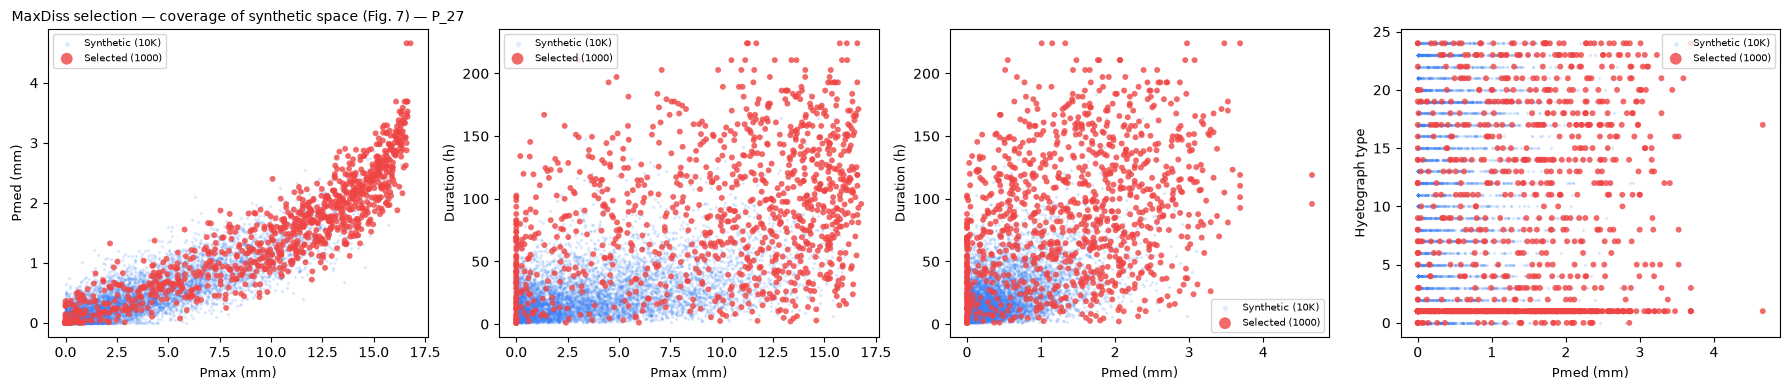

In [2]:
events = pd.read_csv(EVENTS_DIR / 'events_selected.csv', index_col=0)
synth  = pd.read_csv(EVENTS_DIR / 'events_synthetic_sample.csv', index_col=0)

# Gauge P_27 (station 1) — reference in the paper (Figure 7)
sel  = events[['Pmax1','Pmed1','Duracion1','Tipo1']].copy()
samp = synth[['Pmax1','Pmed1','Duracion1','Tipo1']].copy()

print(f'Synthetic pool (~1M, sample available): {len(samp):,}')
print(f'Events selected by MaxDiss: {len(sel)}')
print(f'  Note: Navas et al. (2024) select 625; this dataset contains {len(sel)} events.')

# Reproduce Figure 7 from Navas et al. (2024)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

pairs = [
    ('Pmax1',  'Pmed1',     'Pmax (mm)',  'Pmed (mm)'),
    ('Pmax1',  'Duracion1', 'Pmax (mm)',  'Duration (h)'),
    ('Pmed1',  'Duracion1', 'Pmed (mm)',  'Duration (h)'),
    ('Pmed1',  'Tipo1',     'Pmed (mm)',  'Hyetograph type'),
]

for ax, (xc, yc, xl, yl) in zip(axes, pairs):
    ax.scatter(samp[xc], samp[yc], s=2, alpha=0.12, c='#3b82f6',
               label=f'Synthetic ({len(samp)//1000}K)', rasterized=True)
    ax.scatter(sel[xc],  sel[yc],  s=18, alpha=0.8,  c='#ef4444',
               edgecolors='none', label=f'Selected ({len(sel)})', zorder=3)
    ax.set_xlabel(xl, fontsize=9); ax.set_ylabel(yl, fontsize=9)
    ax.legend(fontsize=7, markerscale=2)

axes[0].set_title('MaxDiss selection — coverage of synthetic space (Fig. 7) — P_27',
                  fontsize=10)
plt.tight_layout(); plt.show()

## MaxDiss with `pyhydra` — 625 events in the full 84-dimensional space

In [3]:
import time
from pyhydra.climate.hybrid_downscaling.reconstruction import maxdiss

N_SELECT = 625   # Navas et al. (2024)

regen_path = EVENTS_DIR / 'events_synthetic_pyhydra.npz'
if regen_path.exists():
    z = np.load(regen_path, allow_pickle=False)
    pool = pd.DataFrame(z['values'].astype(float), columns=z['columns'].astype(str))
    pool_label = 'pyhydra copula catalogue (notebook 03)'
else:   # notebook 03 not run yet: fall back to the archived sample
    pool = synth.copy()
    pool_label = 'archived synthetic sample'

# Min-max normalisation so every variable weighs equally in the distance.
X = pool.to_numpy()
X_n = (X - X.min(0)) / np.where(np.ptp(X, 0) > 0, np.ptp(X, 0), 1.0)

t0 = time.time()
_, sel_idx = maxdiss(X_n, n_select=N_SELECT,
                     scalar_cols=list(range(X_n.shape[1])), seed_positions=[])
print(f'Pool: {pool_label} — {len(pool):,} events × {pool.shape[1]} variables')
print(f'MaxDiss selected {len(sel_idx)} events in {time.time() - t0:.1f} s')
picked = pool.iloc[sel_idx]

# Coverage diagnostic: share of each variable's pool range spanned by the selection.
span = (picked.max() - picked.min()) / (pool.max() - pool.min()).replace(0, np.nan)
print(f'Range covered by the selection: median {span.median():.0%}, minimum {span.min():.0%} '
      f'({span.idxmin()})')

np.save(EVENTS_DIR / 'events_selected_pyhydra_idx.npy', np.asarray(sel_idx))


Pool: pyhydra copula catalogue (notebook 03) — 100,000 events × 84 variables
MaxDiss selected 625 events in 36.5 s
Range covered by the selection: median 100%, minimum 80% (lags_2)


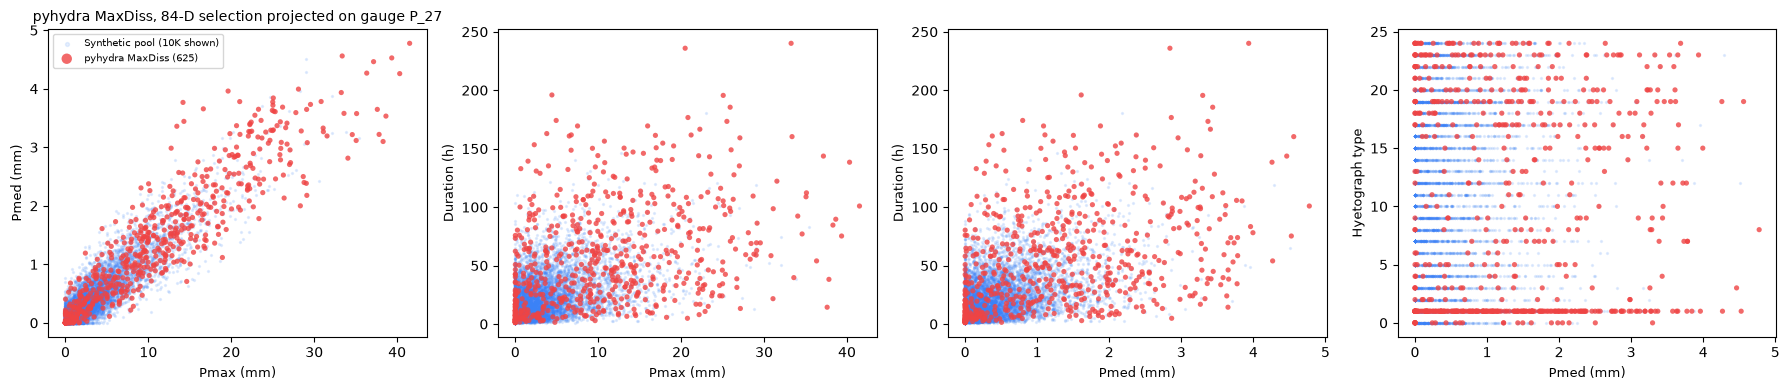

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
pairs = [
    ('Pmax1', 'Pmed1',     'Pmax (mm)', 'Pmed (mm)'),
    ('Pmax1', 'Duracion1', 'Pmax (mm)', 'Duration (h)'),
    ('Pmed1', 'Duracion1', 'Pmed (mm)', 'Duration (h)'),
    ('Pmed1', 'Tipo1',     'Pmed (mm)', 'Hyetograph type'),
]
show = pool.sample(min(len(pool), 10_000), random_state=0)
for ax, (xc, yc, xl, yl) in zip(axes, pairs):
    ax.scatter(show[xc], show[yc], s=2, alpha=0.12, c='#3b82f6', rasterized=True,
               label='Synthetic pool (10K shown)')
    ax.scatter(picked[xc], picked[yc], s=14, alpha=0.8, c='#ef4444',
               edgecolors='none', label=f'pyhydra MaxDiss ({len(picked)})', zorder=3)
    ax.set_xlabel(xl, fontsize=9); ax.set_ylabel(yl, fontsize=9)
axes[0].legend(fontsize=7, markerscale=2)
axes[0].set_title('pyhydra MaxDiss, 84-D selection projected on gauge P_27', fontsize=10)
plt.tight_layout(); plt.show()


The selection concentrates on the edges and corners of the synthetic space, which is the purpose of MaxDiss. It is the design that is simulated with the expensive hydrological and hydraulic models.

**Scope.** The HEC-HMS and HEC-RAS runs of the 2024 study were made for its own selection. They are not re-executed here; notebooks 05–06 document those archived results.